In [ ]:
from google.colab import files
uploaded = files.upload()


Saving employee_attrition_prediction_dataset.csv to employee_attrition_prediction_dataset (1).csv


In [ ]:
import pandas as pd
df = pd.read_csv("employee_attrition_prediction_dataset.csv")
print(df.shape)
df.head()


(500, 21)


,EmployeeID,Age,Department,JobRole,MonthlyIncome,DistanceFromHome,BusinessTravel,OverTime,JobSatisfaction,EnvironmentSatisfaction,...,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,TotalWorkingYears,TrainingTimesLastYear,PerformanceRating,StockOptionLevel,MaritalStatus,Gender,Attrition
0,EMP0001,26,IT,Software Engineer,8259,3,Travel_Rarely,No,3,4,...,6,3,1,8,1,3,3,Married,Male,No
1,EMP0002,32,IT,Data Analyst,5069,4,Travel_Rarely,No,3,4,...,2,0,1,12,6,4,1,Single,Female,No
2,EMP0003,36,IT,Software Engineer,6876,22,Travel_Rarely,Yes,4,3,...,4,0,3,11,5,3,1,Married,Male,No
3,EMP0004,41,Research & Development,Research Scientist,9573,9,Travel_Rarely,No,4,2,...,2,1,1,8,2,3,0,Single,Male,No
4,EMP0005,38,IT,Data Analyst,4756,3,Travel_Rarely,No,2,3,...,4,4,3,19,1,3,0,Single,Male,No


In [ ]:
# 1. Dataset size
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns)

# 3. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 5. Attrition count
print("\nAttrition Count:")
print(df["Attrition"].value_counts())

Dataset Shape: (500, 21)

Column Names:
Index(['EmployeeID', 'Age', 'Department', 'JobRole', 'MonthlyIncome',
       'DistanceFromHome', 'BusinessTravel', 'OverTime', 'JobSatisfaction',
       'EnvironmentSatisfaction', 'WorkLifeBalance', 'YearsAtCompany',
       'YearsInCurrentRole', 'YearsSinceLastPromotion', 'TotalWorkingYears',
       'TrainingTimesLastYear', 'PerformanceRating', 'StockOptionLevel',
       'MaritalStatus', 'Gender', 'Attrition'],
      dtype='object')

Missing Values:
EmployeeID                 0
Age                        0
Department                 0
JobRole                    0
MonthlyIncome              0
DistanceFromHome           0
BusinessTravel             0
OverTime                   0
JobSatisfaction            0
EnvironmentSatisfaction    0
WorkLifeBalance            0
YearsAtCompany             0
YearsInCurrentRole         0
YearsSinceLastPromotion    0
TotalWorkingYears          0
TrainingTimesLastYear      0
PerformanceRating          0
StockOptionLe

In [ ]:
attrition_percentage = (
  df["Attrition"].value_counts(normalize=True) * 100
  )
print(attrition_percentage.round(2))

Attrition
No     78.4
Yes    21.6
Name: proportion, dtype: float64


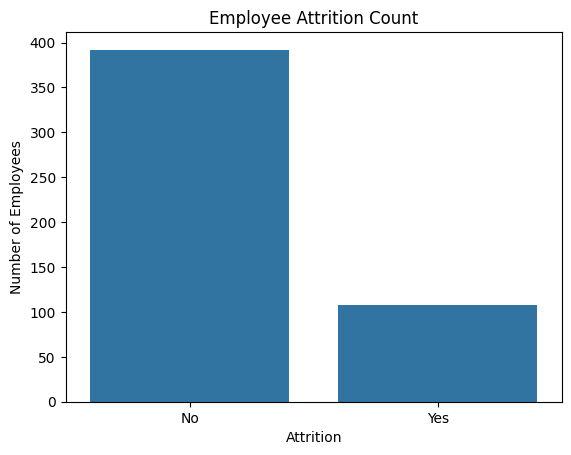

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Count")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

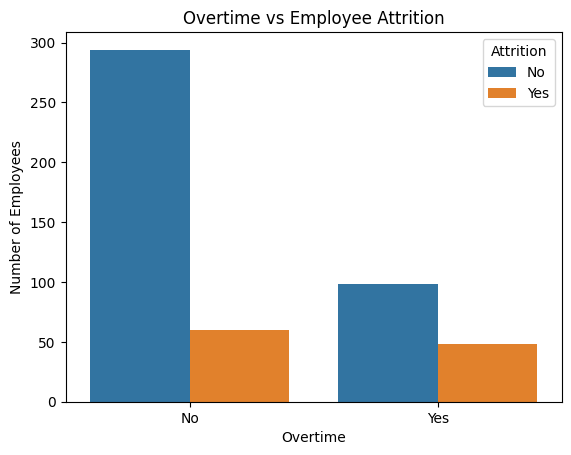

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="OverTime", hue="Attrition")

plt.title("Overtime vs Employee Attrition")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")
plt.show()

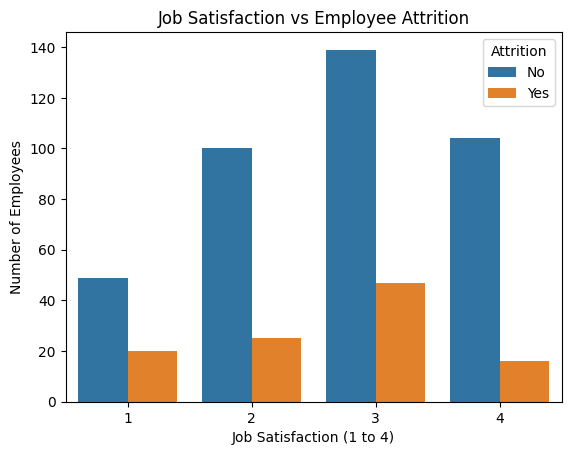

In [ ]:
sns.countplot(data=df, x="JobSatisfaction", hue="Attrition")

plt.title("Job Satisfaction vs Employee Attrition")
plt.xlabel("Job Satisfaction (1 to 4)")
plt.ylabel("Number of Employees")
plt.show()

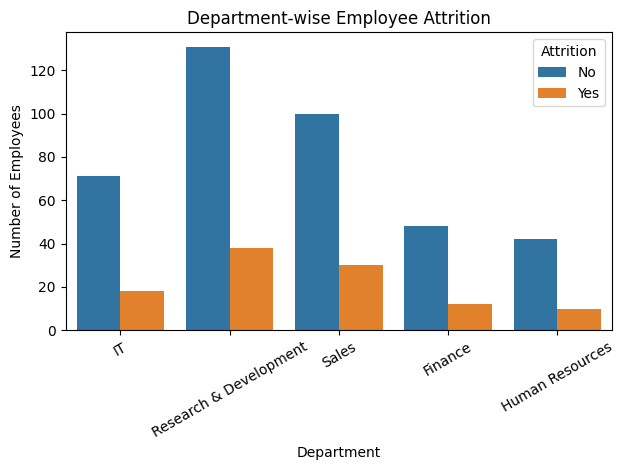

In [ ]:
sns.countplot(data=df, x="Department", hue="Attrition")

plt.title("Department-wise Employee Attrition")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Attrition                  No    Yes
Department                          
Finance                 80.00  20.00
Human Resources         80.77  19.23
IT                      79.78  20.22
Research & Development  77.51  22.49
Sales                   76.92  23.08


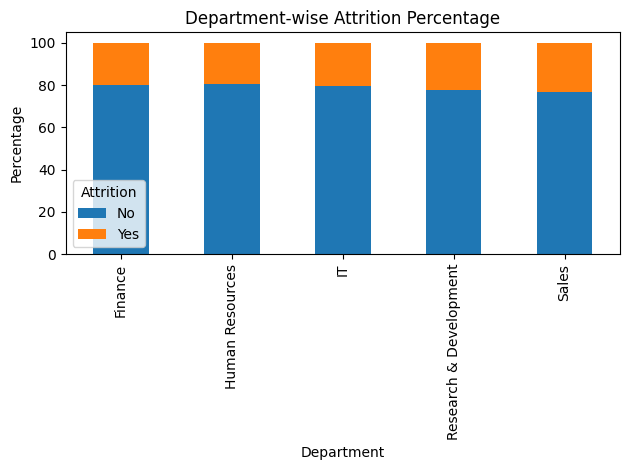

In [ ]:
department_attrition = (
      pd.crosstab(df["Department"], df["Attrition"], normalize="index") * 100
      )
print(department_attrition.round(2))
department_attrition.plot(kind="bar", stacked=True)
plt.title("Department-wise Attrition Percentage")
plt.ylabel("Percentage")
plt.xlabel("Department")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Copy dataset
data = df.copy()

# Remove employee ID
data = data.drop("EmployeeID", axis=1)

# Convert text columns into numbers
data = pd.get_dummies(data, drop_first=True, dtype=int)

# Separate input and output
X = data.drop("Attrition_Yes", axis=1)
y = data["Attrition_Yes"]

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
        test_size=0.2,
            random_state=42,
                stratify=y
                )
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Input features:", X_train.shape[1])

Training records: 400
Testing records: 100
Input features: 37


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000, random_state=42)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
from sklearn.metrics import (
      accuracy_score,
          classification_report,
              confusion_matrix
              )
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 75.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.95      0.86        78
           1       0.20      0.05      0.07        22

    accuracy                           0.75       100
   macro avg       0.49      0.50      0.46       100
weighted avg       0.65      0.75      0.68       100


Confusion Matrix:
[[74  4]
 [21  1]]


            Predicted No  Predicted Yes
Actual No             74              4
Actual Yes            21              1


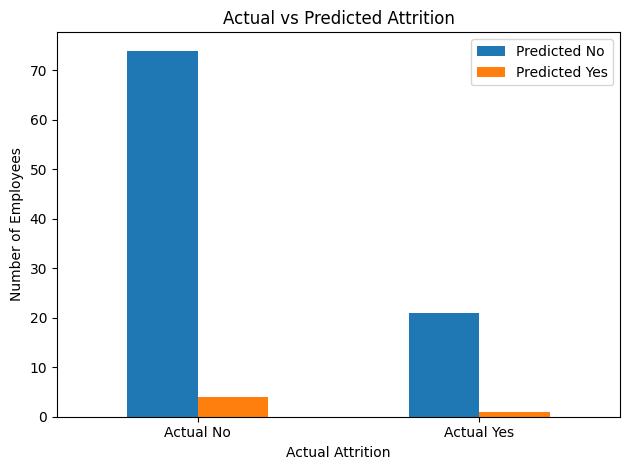

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Actual": y_test.values,
        "Predicted": y_pred
        })
comparison_counts = pd.crosstab(
      comparison["Actual"],
      comparison["Predicted"]
                )
comparison_counts.index = ["Actual No", "Actual Yes"]
comparison_counts.columns = ["Predicted No", "Predicted Yes"]
print(comparison_counts)
comparison_counts.plot(kind="bar")
plt.title("Actual vs Predicted Attrition")
plt.xlabel("Actual Attrition")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
new_employee = X_test.iloc[[0]]

prediction = model.predict(new_employee)[0]
probability = model.predict_proba(new_employee)[0]

print("Predicted Attrition:", "Yes" if prediction == 1 else "No")
print("Estimated probability of Attrition: {:.2f}%".format(
    probability[list(model.classes_).index(1)] * 100
    ))

Predicted Attrition: No
Estimated probability of Attrition: 14.50%


In [ ]:
import joblib
joblib.dump(model, "employee_attrition_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files
files.download("employee_attrition_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>